DAY 2


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import cv2

print('NumPy:', np.__version__)
print('OpenCV:', cv2.__version__)


NumPy: 2.1.3
OpenCV: 5.0.0


## digital image

A digital image is a grid of **pixels**. Each pixel stores a value (or several values for a colour image). A grayscale image has one intensity value per pixel; a typical RGB image has red, green, and blue values per pixel.

- **Height:** number of pixel rows.
- **Width:** number of pixel columns.
- **Channels:** values stored at each pixel (often 1 for grayscale or 3 for RGB/BGR).
- **Resolution:** width × height, such as 640 × 480.
- **Data type (`dtype`):** often `uint8`, storing integers from 0 to 255.

For an RGB image, array shape is usually `(height, width, 3)`, not `(width, height, 3)`.


Shape (height, width, channels): (100, 150, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


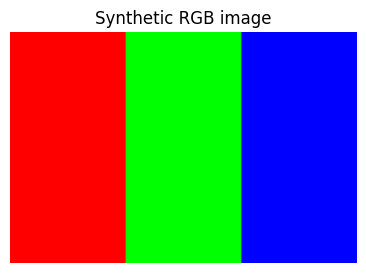

In [2]:
# Create a tiny synthetic RGB image: 100 pixels high, 150 wide, 3 channels
image_array = np.zeros((100, 150, 3), dtype=np.uint8)
image_array[:, :50] = [255, 0, 0]       # red region
image_array[:, 50:100] = [0, 255, 0]   # green region
image_array[:, 100:] = [0, 0, 255]    # blue region

print('Shape (height, width, channels):', image_array.shape)
print('Data type:', image_array.dtype)
print('Minimum pixel value:', image_array.min())
print('Maximum pixel value:', image_array.max())
plt.figure(figsize=(6, 3))
plt.imshow(image_array)
plt.title('Synthetic RGB image')
plt.axis('off');
plt.show()


## Load and inspect an image with Pillow


Saving download.png to download.png
Format: PNG
Mode: RGBA
Size (width, height): (366, 273)


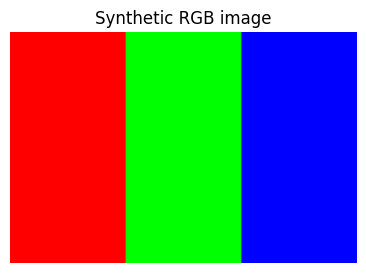

In [3]:
from google.colab import files

uploaded = files.upload()
if uploaded:
    image_path = next(iter(uploaded))
    pil_image = Image.open(image_path)
    print('Format:', pil_image.format)
    print('Mode:', pil_image.mode)  # e.g. RGB, RGBA, or L
    print('Size (width, height):', pil_image.size)
    display(pil_image)
else:
    pil_image = Image.fromarray(image_array)
    print('Using the synthetic image instead.')


In [4]:
rgb_image = pil_image.convert('RGB')
rgb_array = np.array(rgb_image)
print('Pillow size (W, H):', rgb_image.size)
print('NumPy shape (H, W, C):', rgb_array.shape)
print('NumPy dtype:', rgb_array.dtype)


Pillow size (W, H): (366, 273)
NumPy shape (H, W, C): (273, 366, 3)
NumPy dtype: uint8


## Resizing images


Original size (W, H): (366, 273)
Resized size (W, H): (128, 128)


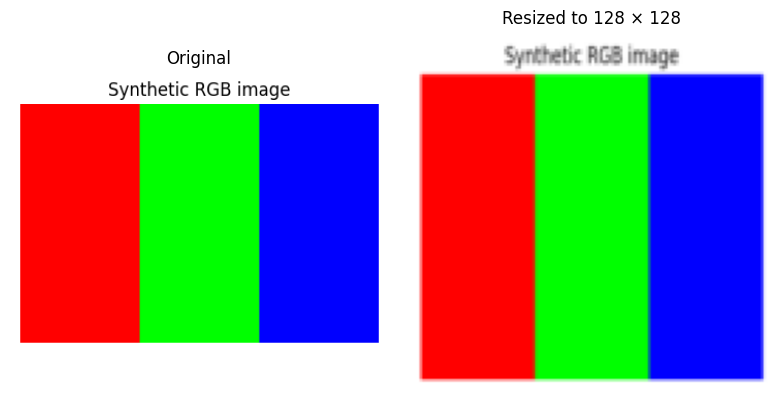

In [5]:
resized_image = rgb_image.resize((128, 128), Image.Resampling.BILINEAR)
print('Original size (W, H):', rgb_image.size)
print('Resized size (W, H):', resized_image.size)
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(rgb_image); axes[0].set_title('Original')
axes[1].imshow(resized_image); axes[1].set_title('Resized to 128 × 128')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()


## RGB and BGR: a common OpenCV gotcha

Pillow and Matplotlib normally use **RGB** channel order. OpenCV (`cv2`) typically loads colour images as **BGR**. Displaying a BGR array directly with Matplotlib can make colours look wrong.


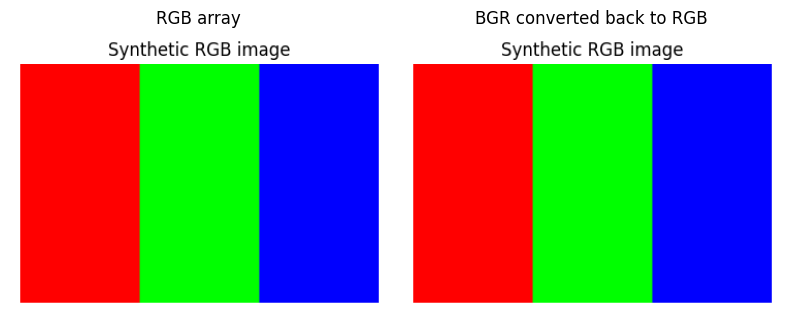

Conversion preserves shape: True
Pixel arrays match after round trip: True


In [6]:
# Convert RGB -> BGR and back to RGB for correct Matplotlib display
bgr_array = cv2.cvtColor(rgb_array, cv2.COLOR_RGB2BGR)
converted_back = cv2.cvtColor(bgr_array, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(rgb_array); axes[0].set_title('RGB array')
axes[1].imshow(converted_back); axes[1].set_title('BGR converted back to RGB')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()
print('Conversion preserves shape:', converted_back.shape == rgb_array.shape)
print('Pixel arrays match after round trip:', np.array_equal(converted_back, rgb_array))


## Grayscale and pixel values

A grayscale image has one intensity channel. OpenCV can convert an RGB image to grayscale. The resulting image is usually represented as a 2D array `(height, width)`.


Grayscale shape: (273, 366)
Grayscale dtype: uint8
Example pixel intensity: 255


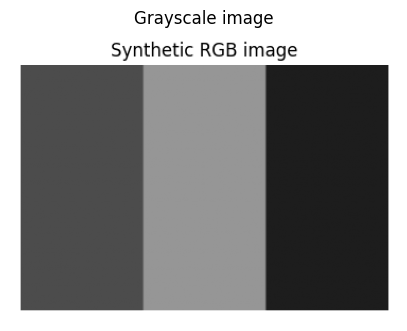

In [7]:
gray_array = cv2.cvtColor(rgb_array, cv2.COLOR_RGB2GRAY)
print('Grayscale shape:', gray_array.shape)
print('Grayscale dtype:', gray_array.dtype)
print('Example pixel intensity:', int(gray_array[0, 0]))
plt.figure(figsize=(5, 4))
plt.imshow(gray_array, cmap='gray', vmin=0, vmax=255)
plt.title('Grayscale image')
plt.axis('off'); plt.show()


## Normalize pixel values

`uint8` images commonly use values from 0 to 255. Many ML pipelines convert them to floating point and scale them to `[0, 1]` by dividing by 255. This is called normalization. It changes the numeric scale, not the image's dimensions. Other pipelines use dataset-specific means and standard deviations; `[0, 1]` is the basic example here.


In [8]:
normalized = rgb_array.astype(np.float32) / 255.0
print('Before:', rgb_array.dtype, int(rgb_array.min()), int(rgb_array.max()))
print('After:', normalized.dtype, float(normalized.min()), float(normalized.max()))
print('Shape unchanged:', normalized.shape == rgb_array.shape)


Before: uint8 0 255
After: float32 0.0 1.0
Shape unchanged: True


## exercises


1. Create a NumPy array representing a 64 × 64 RGB image filled with black pixels. Print its shape and data type.
2. Set the top-left 16 × 16 region to white and display it.
3. Resize your uploaded (or synthetic) image to 64 × 64 and verify its size and array shape.
4. Convert it to grayscale and state its shape.
5. Normalize the RGB array to `[0, 1]`; verify the minimum and maximum values.
6. In your own words, explain the RGB/BGR difference and why channel order matters.


Shape: (64, 64, 3)
Data type: uint8


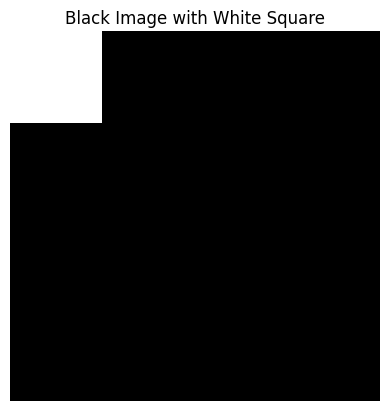

In [9]:

# Create a 64 × 64 RGB image filled with black
black_image = np.zeros((64, 64, 3), dtype=np.uint8)

print("Shape:", black_image.shape)
print("Data type:", black_image.dtype)

# Set the top-left 16 × 16 region to white
black_image[:16, :16] = [255, 255, 255]

# Display the image
plt.imshow(black_image)
plt.title("Black Image with White Square")
plt.axis("off")
plt.show()


Resized image size (W, H): (64, 64)
RGB array shape: (64, 64, 3)
Grayscale shape: (64, 64)
Normalized dtype: float32
Minimum: 0.0
Maximum: 1.0


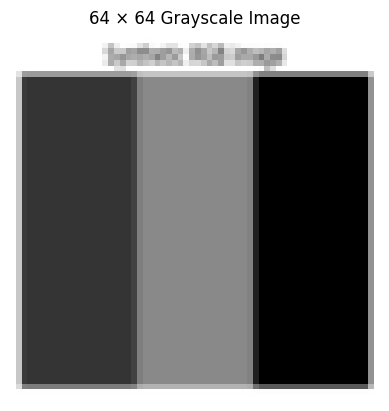

In [11]:

# Resize the RGB image to 64 × 64
resized_64 = rgb_image.resize((64, 64), Image.Resampling.BILINEAR)

# Convert the resized image to a NumPy array
resized_array = np.array(resized_64)

print("Resized image size (W, H):", resized_64.size)
print("RGB array shape:", resized_array.shape)

# Convert RGB to grayscale
gray_64 = cv2.cvtColor(resized_array, cv2.COLOR_RGB2GRAY)
print("Grayscale shape:", gray_64.shape)

# Normalize RGB values to [0, 1]
normalized_64 = resized_array.astype(np.float32) / 255.0
print("Normalized dtype:", normalized_64.dtype)
print("Minimum:", normalized_64.min())
print("Maximum:", normalized_64.max())

# Display grayscale image
plt.imshow(gray_64, cmap="gray")
plt.title("64 × 64 Grayscale Image")
plt.axis("off")
plt.show()


## Day 2 summary

explain and demonstrate:
- What pixels, image dimensions, and channels represent.
- The difference between Pillow size `(W, H)` and NumPy shape `(H, W, C)`.
- The usual `uint8` range (0–255) and normalization to `[0, 1]`.
- How to load, inspect, resize, and display an image.
- How to convert RGB ↔ BGR and RGB → grayscale.

